In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv')

In [3]:
print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())


Dataset shape: (10000, 10)

First five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [4]:
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

Data types:
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Target                       int64
Failure Type                object
dtype: object

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

Duplicate rows: 0


In [5]:
# Make a copy to preserve the original dataset
data = df.copy()

# Remove duplicate rows, if any
data = data.drop_duplicates()

# Remove identifier columns
data = data.drop(columns=["UDI", "Product ID"])

# Inspect the target classes before encoding
print("Failure Type distribution:")
display(data["Failure Type"].value_counts())

print("\nFailure Type percentages:")
display(
    (data["Failure Type"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nRemaining columns:")
print(data.columns.tolist())

print("\nDataset shape after removing identifiers:", data.shape)


Failure Type distribution:


Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


Failure Type percentages:


Failure Type
No Failure                  96.52
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45
Random Failures              0.18
Name: proportion, dtype: float64


Remaining columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']

Dataset shape after removing identifiers: (10000, 8)


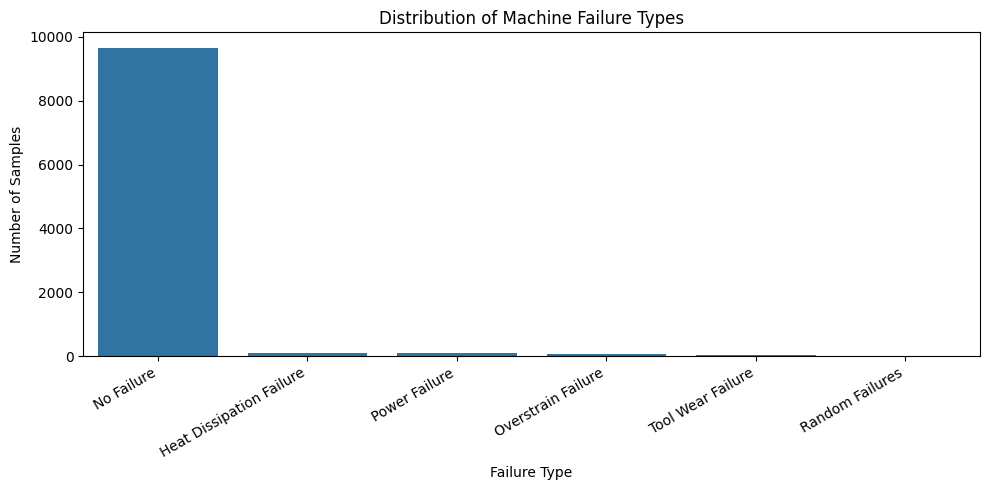

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))

order = data["Failure Type"].value_counts().index

sns.countplot(
    data=data,
    x="Failure Type",
    order=order
)

plt.title("Distribution of Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target']


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


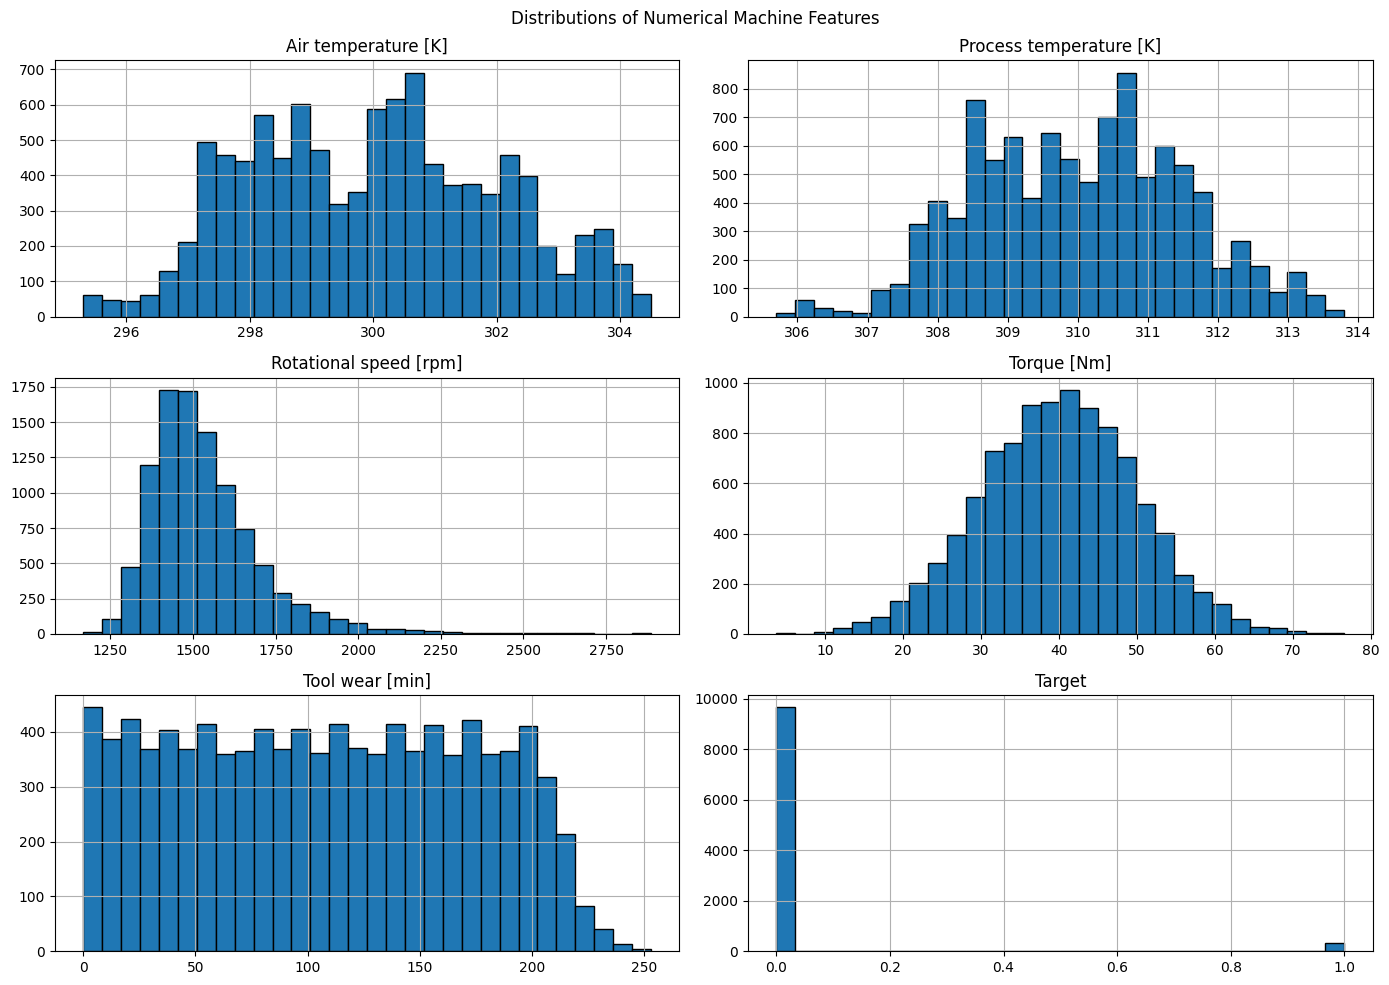

In [7]:

numerical_cols = data.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:", numerical_cols)

display(data[numerical_cols].describe())

# Feature distributions
data[numerical_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Machine Features")
plt.tight_layout()
plt.show()


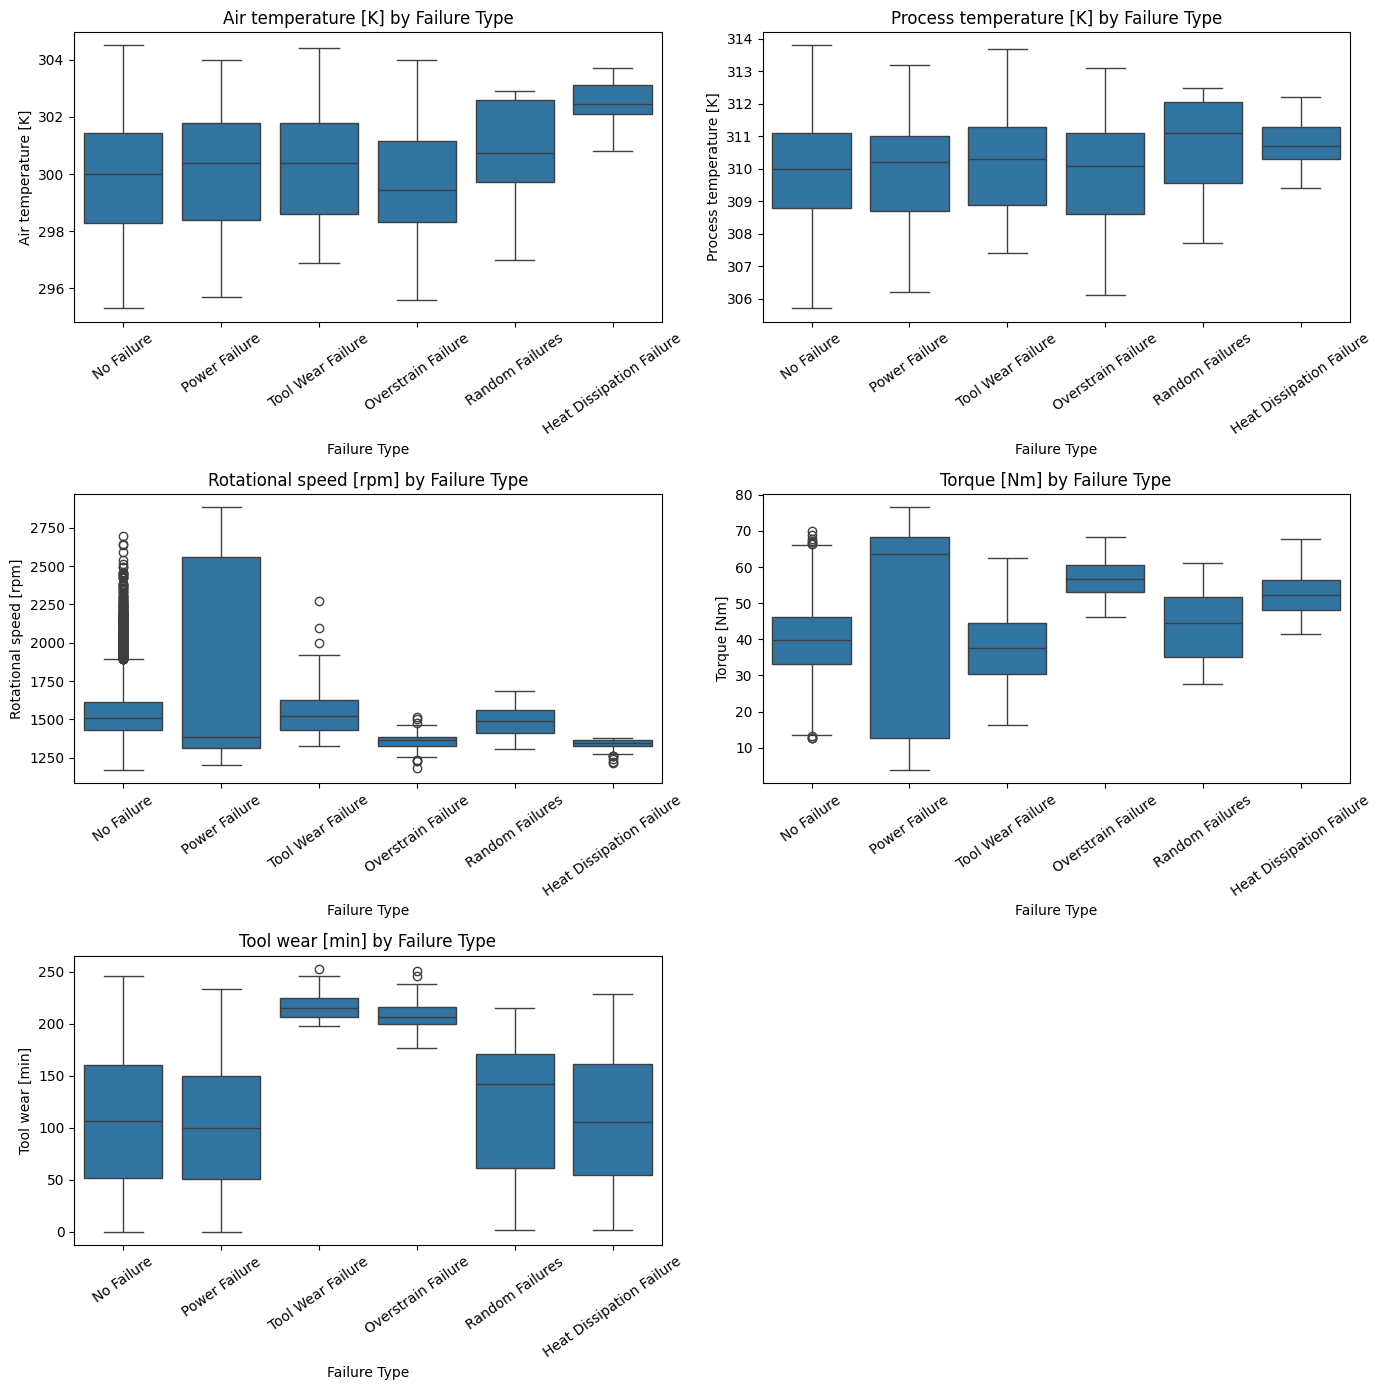

In [8]:

features_to_plot = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.boxplot(
        data=data,
        x="Failure Type",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} by Failure Type")
    axes[i].tick_params(axis="x", rotation=35)

axes[-1].axis("off")
plt.tight_layout()
plt.show()


In [9]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Separate input features and target
X = data.drop(columns=["Failure Type", "Target"]).copy()
y = data["Failure Type"].copy()

# Encode categorical input feature
X = pd.get_dummies(X, columns=["Type"], dtype=int)

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Input features:")
print(X.columns.tolist())

print("\nTarget classes:")
for i, name in enumerate(label_encoder.classes_):
    print(f"{i}: {name}")

print("\nX shape:", X.shape)
print("y shape:", y_encoded.shape)


Input features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']

Target classes:
0: Heat Dissipation Failure
1: No Failure
2: Overstrain Failure
3: Power Failure
4: Random Failures
5: Tool Wear Failure

X shape: (10000, 8)
y shape: (10000,)


In [10]:

# First: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

# Then: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining class counts:")
print(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts())


Training set: (7000, 8)
Validation set: (1500, 8)
Test set: (1500, 8)

Training class counts:
No Failure                  6756
Heat Dissipation Failure      78
Power Failure                 67
Overstrain Failure            55
Tool Wear Failure             31
Random Failures               13
Name: count, dtype: int64


In [11]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

print("\nTraining feature means (approximately zero):")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nTraining feature standard deviations (approximately one):")
print(np.round(X_train_scaled.std(axis=0), 3))


Scaled training shape: (7000, 8)
Scaled validation shape: (1500, 8)
Scaled test shape: (1500, 8)

Training feature means (approximately zero):
[ 0. -0.  0. -0.  0. -0. -0. -0.]

Training feature standard deviations (approximately one):
[1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
# Balance the training set only
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_scaled,
    y_train
)

print("Before balancing:")
print(Counter(y_train))

print("\nAfter balancing:")
print(Counter(y_train_balanced))

print("\nBalanced training shape:", X_train_balanced.shape)


Before balancing:
Counter({np.int64(1): 6756, np.int64(0): 78, np.int64(3): 67, np.int64(2): 55, np.int64(5): 31, np.int64(4): 13})

After balancing:
Counter({np.int64(1): 6756, np.int64(0): 6756, np.int64(5): 6756, np.int64(3): 6756, np.int64(2): 6756, np.int64(4): 6756})

Balanced training shape: (40536, 8)


In [13]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_balanced, dtype=torch.float32
)
y_train_tensor = torch.tensor(
    y_train_balanced, dtype=torch.long
)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Create training batches
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(y_val_tensor))
print("Test samples:", len(y_test_tensor))
print("Input features:", X_train_tensor.shape[1])
print("Number of classes:", len(label_encoder.classes_))

Using device: cpu
Training samples: 40536
Validation samples: 1500
Test samples: 1500
Input features: 8
Number of classes: 6


In [14]:

class MaintenanceDNN(nn.Module):
    def __init__(self, input_dim=8, num_classes=6):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


model = MaintenanceDNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)


MaintenanceDNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [15]:

from copy import deepcopy

# Reinitialize the baseline model and optimizer
torch.manual_seed(42)

model = MaintenanceDNN(input_dim=8, num_classes=6).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 20

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):
    # ---------- Training ----------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()

        outputs = model(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * xb.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == yb).sum().item()
        train_total += yb.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------- Validation ----------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for start in range(0, len(X_val_tensor), 256):
            xb = X_val_tensor[start:start + 256].to(device)
            yb = y_val_tensor[start:start + 256].to(device)

            outputs = model(xb)
            loss = criterion(outputs, yb)

            val_loss_sum += loss.item() * xb.size(0)
            val_correct += (
                outputs.argmax(dim=1) == yb
            ).sum().item()
            val_total += yb.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Save the best model using validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = deepcopy(model.state_dict())
        best_epoch = epoch + 1

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")


Epoch [01/20] Train Loss: 0.7834 | Train Acc: 0.7396 | Val Loss: 0.8484 | Val Acc: 0.6140
Epoch [02/20] Train Loss: 0.2962 | Train Acc: 0.9091 | Val Loss: 0.6213 | Val Acc: 0.7240
Epoch [03/20] Train Loss: 0.2083 | Train Acc: 0.9380 | Val Loss: 0.4900 | Val Acc: 0.7793
Epoch [04/20] Train Loss: 0.1585 | Train Acc: 0.9607 | Val Loss: 0.4899 | Val Acc: 0.8040
Epoch [05/20] Train Loss: 0.1264 | Train Acc: 0.9697 | Val Loss: 0.4129 | Val Acc: 0.8460
Epoch [06/20] Train Loss: 0.1051 | Train Acc: 0.9755 | Val Loss: 0.4209 | Val Acc: 0.8473
Epoch [07/20] Train Loss: 0.0901 | Train Acc: 0.9790 | Val Loss: 0.3558 | Val Acc: 0.8827
Epoch [08/20] Train Loss: 0.0807 | Train Acc: 0.9811 | Val Loss: 0.2901 | Val Acc: 0.8953
Epoch [09/20] Train Loss: 0.0720 | Train Acc: 0.9832 | Val Loss: 0.3530 | Val Acc: 0.8927
Epoch [10/20] Train Loss: 0.0659 | Train Acc: 0.9844 | Val Loss: 0.3633 | Val Acc: 0.8907
Epoch [11/20] Train Loss: 0.0609 | Train Acc: 0.9857 | Val Loss: 0.3749 | Val Acc: 0.8920
Epoch [12/

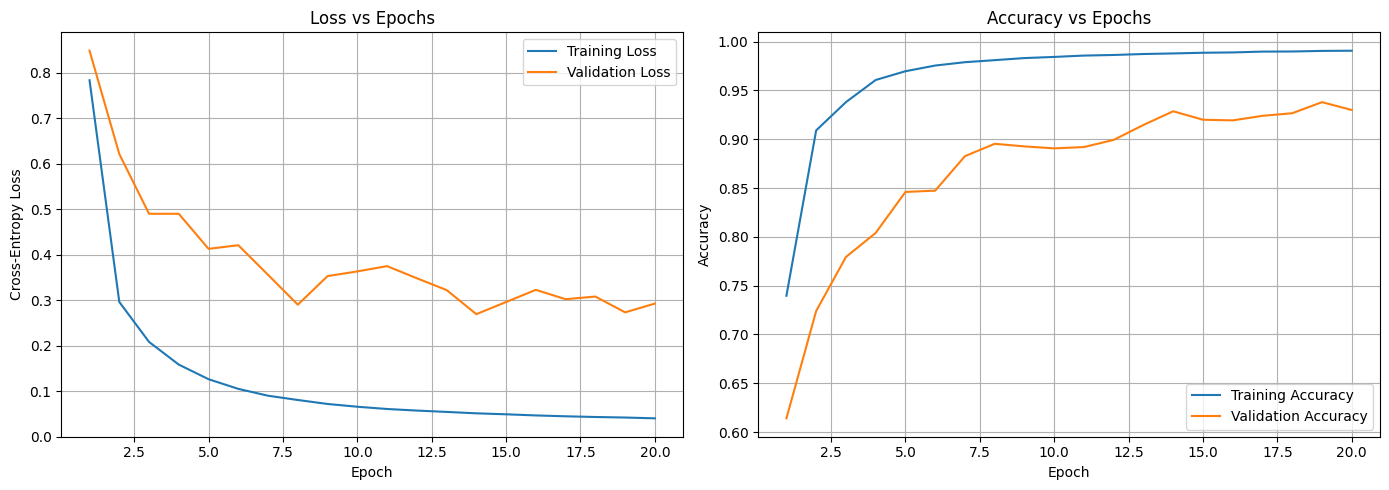

In [16]:

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, history["train_loss"], label="Training Loss")
axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss vs Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy curves
axes[1].plot(epochs, history["train_acc"], label="Training Accuracy")
axes[1].plot(epochs, history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Accuracy vs Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [17]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

# Predict on the untouched test set
model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor.to(device))
    y_pred = test_logits.argmax(dim=1).cpu().numpy()

y_true = y_test

# Overall metrics
print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")

# Per-class precision, recall (sensitivity), and F1-score
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0,
    digits=4
))


Test Accuracy: 0.9347
Balanced Accuracy: 0.7415

Classification Report:
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.4444    0.9412    0.6038        17
              No Failure     0.9971    0.9365    0.9658      1448
      Overstrain Failure     0.6667    1.0000    0.8000        12
           Power Failure     0.6364    1.0000    0.7778        14
         Random Failures     0.0000    0.0000    0.0000         2
       Tool Wear Failure     0.0870    0.5714    0.1509         7

                accuracy                         0.9347      1500
               macro avg     0.4719    0.7415    0.5497      1500
            weighted avg     0.9792    0.9347    0.9535      1500



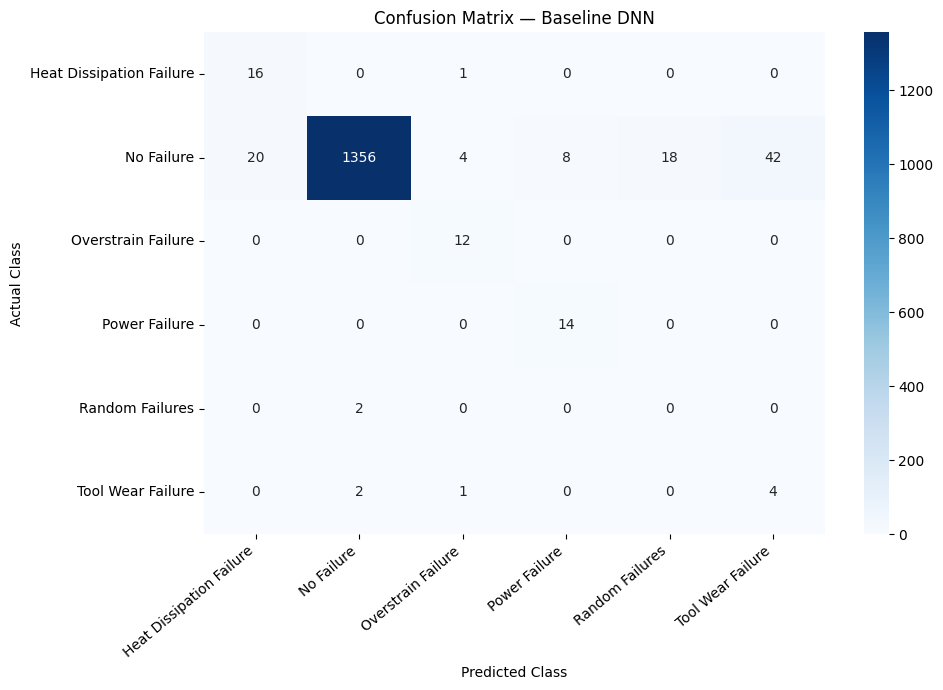

In [18]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix — Baseline DNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:
!pip -q install skorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 6.3 MB/s eta 0:00:00


In [20]:

from skorch import NeuralNetClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import f1_score, make_scorer

class TunableMaintenanceDNN(nn.Module):
    def __init__(self, input_dim=8, num_classes=6,
                 hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, num_classes)
        )

    def forward(self, x):
        return self.network(x)


In [21]:

# Select a stratified subset of the balanced training data
X_search, _, y_search, _ = train_test_split(
    X_train_balanced,
    y_train_balanced,
    train_size=9000,
    random_state=42,
    stratify=y_train_balanced
)

net = NeuralNetClassifier(
    TunableMaintenanceDNN,
    module__input_dim=8,
    module__num_classes=6,
    max_epochs=8,
    batch_size=256,
    lr=0.001,
    optimizer=torch.optim.Adam,
    iterator_train__shuffle=True,
    train_split=None,
    device="cpu",
    verbose=0
)

param_grid = {
    "module__hidden1": [32, 64],
    "module__hidden2": [16, 32],
    "lr": [0.001, 0.01],
    "optimizer": [torch.optim.Adam, torch.optim.SGD]
}

grid_search = GridSearchCV(
    estimator=net,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    refit=True,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_search.astype(np.float32), y_search)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1:")
print(round(grid_search.best_score_, 4))

print("\nAll configurations:")
grid_results = pd.DataFrame(grid_search.cv_results_)

display(
    grid_results[
        ["param_module__hidden1", "param_module__hidden2",
         "param_lr", "param_optimizer", "mean_test_score",
         "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
)


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters:
{'lr': 0.01, 'module__hidden1': 32, 'module__hidden2': 32, 'optimizer': <class 'torch.optim.sgd.SGD'>}

Best cross-validation macro F1:
0.1788

All configurations:


,param_module__hidden1,param_module__hidden2,param_lr,param_optimizer,mean_test_score,std_test_score,rank_test_score
11,32,32,0.010,<class 'torch.optim.sgd.SGD'>,0.178843,0.077321,1
1,32,16,0.001,<class 'torch.optim.sgd.SGD'>,0.139168,0.023403,2
7,64,32,0.001,<class 'torch.optim.sgd.SGD'>,0.129442,0.057929,3
9,32,16,0.010,<class 'torch.optim.sgd.SGD'>,0.127400,0.033620,4
15,64,32,0.010,<class 'torch.optim.sgd.SGD'>,0.112173,0.015890,5
5,64,16,0.001,<class 'torch.optim.sgd.SGD'>,0.106624,0.036300,6
6,64,32,0.001,<class 'torch.optim.adam.Adam'>,0.079953,0.045728,7
13,64,16,0.010,<class 'torch.optim.sgd.SGD'>,0.078644,0.043511,8
4,64,16,0.001,<class 'torch.optim.adam.Adam'>,0.073692,0.036873,9
10,32,32,0.010,<class 'torch.optim.adam.Adam'>,0.067824,0.028574,10


In [22]:

# Best configuration from GridSearchCV
torch.manual_seed(42)

tuned_model = MaintenanceDNN(
    input_dim=8,
    num_classes=6
).to(device)

# Replace the default 64 -> 32 architecture with 32 -> 32
tuned_model.network = nn.Sequential(
    nn.Linear(8, 32),
    nn.ReLU(),
    nn.Linear(32, 32),
    nn.ReLU(),
    nn.Linear(32, 6)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    tuned_model.parameters(),
    lr=0.01
)

tuned_epochs = 30

tuned_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_tuned_loss = float("inf")
best_tuned_state = None

for epoch in range(tuned_epochs):
    tuned_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = tuned_model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * xb.size(0)
        train_correct += (
            outputs.argmax(dim=1) == yb
        ).sum().item()
        train_total += yb.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    tuned_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for start in range(0, len(X_val_tensor), 256):
            xb = X_val_tensor[start:start + 256].to(device)
            yb = y_val_tensor[start:start + 256].to(device)

            outputs = tuned_model(xb)
            loss = criterion(outputs, yb)

            val_loss_sum += loss.item() * xb.size(0)
            val_correct += (
                outputs.argmax(dim=1) == yb
            ).sum().item()
            val_total += yb.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    tuned_history["train_loss"].append(train_loss)
    tuned_history["val_loss"].append(val_loss)
    tuned_history["train_acc"].append(train_acc)
    tuned_history["val_acc"].append(val_acc)

    if val_loss < best_tuned_loss:
        best_tuned_loss = val_loss
        best_tuned_state = deepcopy(tuned_model.state_dict())
        best_tuned_epoch = epoch + 1

    print(
        f"Epoch [{epoch+1:02d}/{tuned_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

tuned_model.load_state_dict(best_tuned_state)

print("\nBest tuned epoch:", best_tuned_epoch)
print("Best tuned validation loss:", round(best_tuned_loss, 4))


Epoch [01/30] Train Loss: 1.7526 | Train Acc: 0.2779 | Val Loss: 1.7859 | Val Acc: 0.0607
Epoch [02/30] Train Loss: 1.5770 | Train Acc: 0.4503 | Val Loss: 1.7017 | Val Acc: 0.2247
Epoch [03/30] Train Loss: 1.3136 | Train Acc: 0.5540 | Val Loss: 1.5405 | Val Acc: 0.3953
Epoch [04/30] Train Loss: 1.0349 | Train Acc: 0.6508 | Val Loss: 1.2998 | Val Acc: 0.5080
Epoch [05/30] Train Loss: 0.8371 | Train Acc: 0.6918 | Val Loss: 1.1174 | Val Acc: 0.5767
Epoch [06/30] Train Loss: 0.7066 | Train Acc: 0.7334 | Val Loss: 0.9979 | Val Acc: 0.6127
Epoch [07/30] Train Loss: 0.6125 | Train Acc: 0.7797 | Val Loss: 0.9440 | Val Acc: 0.6100
Epoch [08/30] Train Loss: 0.5379 | Train Acc: 0.8347 | Val Loss: 0.8853 | Val Acc: 0.6387
Epoch [09/30] Train Loss: 0.4801 | Train Acc: 0.8699 | Val Loss: 0.8622 | Val Acc: 0.6340
Epoch [10/30] Train Loss: 0.4361 | Train Acc: 0.8845 | Val Loss: 0.8403 | Val Acc: 0.6347
Epoch [11/30] Train Loss: 0.4028 | Train Acc: 0.8875 | Val Loss: 0.7836 | Val Acc: 0.6467
Epoch [12/

In [23]:

from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import f1_score, classification_report

tuned_model.eval()

with torch.no_grad():
    tuned_predictions = tuned_model(
        X_test_tensor.to(device)
    ).argmax(dim=1).cpu().numpy()

print("Tuned Test Accuracy:",
      round(accuracy_score(y_test, tuned_predictions), 4))

print("Tuned Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, tuned_predictions), 4))

print("Tuned Macro F1:",
      round(f1_score(y_test, tuned_predictions, average="macro",
                     zero_division=0), 4))

print("\nTuned Classification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0,
    digits=4
))


Tuned Test Accuracy: 0.7627
Tuned Balanced Accuracy: 0.7118
Tuned Macro F1: 0.4113

Tuned Classification Report:
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.2319    0.9412    0.3721        17
              No Failure     0.9964    0.7583    0.8612      1448
      Overstrain Failure     0.3871    1.0000    0.5581        12
           Power Failure     0.4242    1.0000    0.5957        14
         Random Failures     0.0000    0.0000    0.0000         2
       Tool Wear Failure     0.0435    0.5714    0.0808         7

                accuracy                         0.7627      1500
               macro avg     0.3472    0.7118    0.4113      1500
            weighted avg     0.9717    0.7627    0.8459      1500



In [24]:

class RegularizedMaintenanceDNN(nn.Module):
    def __init__(
        self,
        input_dim=8,
        num_classes=6,
        dropout_rate=0.0
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


In [25]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.001
)

In [26]:
model = RegularizedMaintenanceDNN(
    input_dim=8,
    num_classes=6,
    dropout_rate=0.3
).to(device)

In [27]:

import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

def train_regularized_model(
    dropout_rate=0.0,
    weight_decay=0.0,
    epochs=30,
    learning_rate=0.001
):
    model = RegularizedMaintenanceDNN(
        input_dim=8,
        num_classes=6,
        dropout_rate=dropout_rate
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(epochs):
        # Training phase
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            train_correct += (
                outputs.argmax(dim=1) == yb
            ).sum().item()
            train_total += yb.size(0)

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        # Validation phase
        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for start in range(0, len(X_val_tensor), 256):
                xb = X_val_tensor[start:start + 256].to(device)
                yb = y_val_tensor[start:start + 256].to(device)

                outputs = model(xb)
                loss = criterion(outputs, yb)

                val_loss_sum += loss.item() * xb.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == yb
                ).sum().item()
                val_total += yb.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

        print(
            f"Epoch [{epoch + 1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    model.load_state_dict(best_state)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")

    return model, history, best_epoch, best_val_loss


In [28]:

experiments = {
    "Baseline": {
        "dropout_rate": 0.0,
        "weight_decay": 0.0
    },
    "L2 Regularization": {
        "dropout_rate": 0.0,
        "weight_decay": 0.001
    },
    "Dropout": {
        "dropout_rate": 0.3,
        "weight_decay": 0.0
    }
}

trained_models = {}
histories = {}
training_summary = {}

for name, params in experiments.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    torch.manual_seed(42)
    np.random.seed(42)

    model, history, best_epoch, best_val_loss = (
        train_regularized_model(
            dropout_rate=params["dropout_rate"],
            weight_decay=params["weight_decay"],
            epochs=30,
            learning_rate=0.001
        )
    )

    trained_models[name] = model
    histories[name] = history

    training_summary[name] = {
        "Best Epoch": best_epoch,
        "Best Validation Loss": best_val_loss,
        "Final Training Loss": history["train_loss"][-1],
        "Final Validation Loss": history["val_loss"][-1]
    }



Baseline
Epoch [01/30] Train Loss: 0.7834 | Val Loss: 0.8484 | Train Acc: 0.7396 | Val Acc: 0.6140
Epoch [02/30] Train Loss: 0.2962 | Val Loss: 0.6213 | Train Acc: 0.9091 | Val Acc: 0.7240
Epoch [03/30] Train Loss: 0.2083 | Val Loss: 0.4900 | Train Acc: 0.9380 | Val Acc: 0.7793
Epoch [04/30] Train Loss: 0.1585 | Val Loss: 0.4899 | Train Acc: 0.9607 | Val Acc: 0.8040
Epoch [05/30] Train Loss: 0.1264 | Val Loss: 0.4129 | Train Acc: 0.9697 | Val Acc: 0.8460
Epoch [06/30] Train Loss: 0.1051 | Val Loss: 0.4209 | Train Acc: 0.9755 | Val Acc: 0.8473
Epoch [07/30] Train Loss: 0.0901 | Val Loss: 0.3558 | Train Acc: 0.9790 | Val Acc: 0.8827
Epoch [08/30] Train Loss: 0.0807 | Val Loss: 0.2901 | Train Acc: 0.9811 | Val Acc: 0.8953
Epoch [09/30] Train Loss: 0.0720 | Val Loss: 0.3530 | Train Acc: 0.9832 | Val Acc: 0.8927
Epoch [10/30] Train Loss: 0.0659 | Val Loss: 0.3633 | Train Acc: 0.9844 | Val Acc: 0.8907
Epoch [11/30] Train Loss: 0.0609 | Val Loss: 0.3749 | Train Acc: 0.9857 | Val Acc: 0.8920


In [29]:

results = {}
predictions_by_model = {}

for name, model in trained_models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(X_test_tensor.to(device))
        predictions = outputs.argmax(dim=1).cpu().numpy()

    predictions_by_model[name] = predictions

    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    }

    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0,
        digits=4
    ))



Baseline
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.4444    0.9412    0.6038        17
              No Failure     0.9971    0.9365    0.9658      1448
      Overstrain Failure     0.6667    1.0000    0.8000        12
           Power Failure     0.6364    1.0000    0.7778        14
         Random Failures     0.0000    0.0000    0.0000         2
       Tool Wear Failure     0.0870    0.5714    0.1509         7

                accuracy                         0.9347      1500
               macro avg     0.4719    0.7415    0.5497      1500
            weighted avg     0.9792    0.9347    0.9535      1500


L2 Regularization
                          precision    recall  f1-score   support

Heat Dissipation Failure     0.3636    0.9412    0.5246        17
              No Failure     0.9962    0.9164    0.9547      1448
      Overstrain Failure     0.6000    1.0000    0.7500        12
           Power Failure     0.4828    1.00

In [30]:

import pandas as pd

results_df = pd.DataFrame(results).T
training_df = pd.DataFrame(training_summary).T

comparison_df = training_df.join(results_df)

comparison_df = comparison_df.round(4)
display(comparison_df)


,Best Epoch,Best Validation Loss,Final Training Loss,Final Validation Loss,Accuracy,Balanced Accuracy,Macro F1
Baseline,14.0,0.2693,0.0310,0.2732,0.9347,0.7415,0.5497
L2 Regularization,28.0,0.2478,0.0623,0.2613,0.9147,0.7144,0.4983
Dropout,28.0,0.3732,0.1254,0.3789,0.8760,0.7077,0.4540


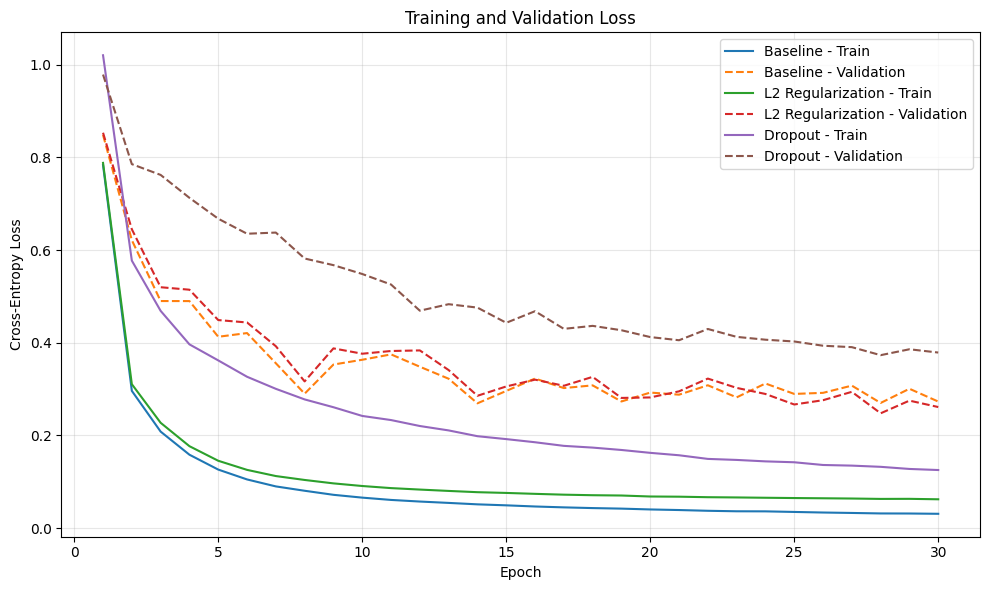

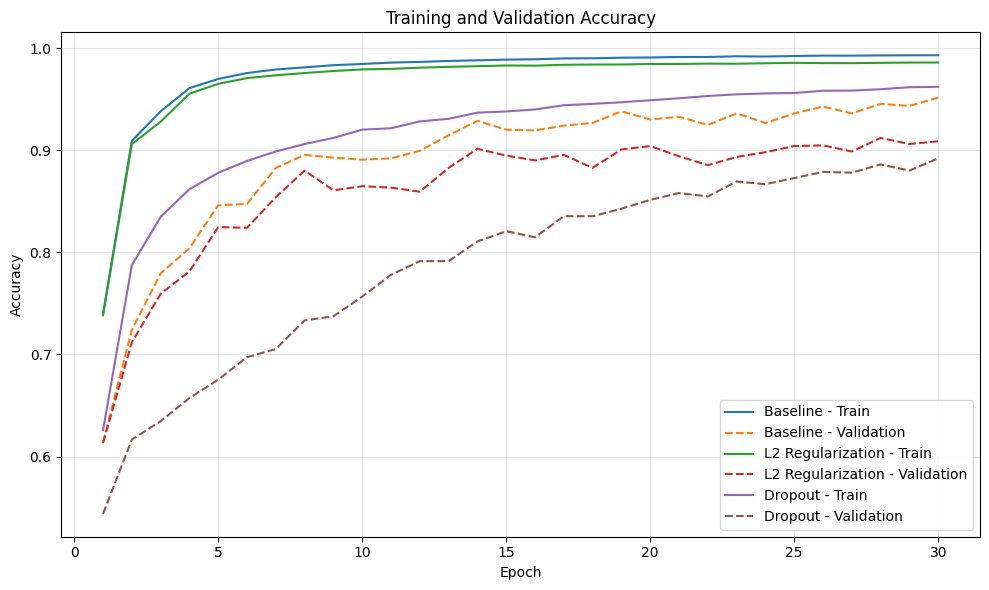

In [31]:

import matplotlib.pyplot as plt

# Loss curves
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.plot(
        epochs_range,
        history["train_loss"],
        label=f"{name} - Train"
    )
    plt.plot(
        epochs_range,
        history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Accuracy curves
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    epochs_range = range(1, len(history["train_acc"]) + 1)

    plt.plot(
        epochs_range,
        history["train_acc"],
        label=f"{name} - Train"
    )
    plt.plot(
        epochs_range,
        history["val_acc"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
